#1.	Data Exploration & Preprocessing
## 1.1	Load the Dataset
## 1.2	Explore the Dataset
Perform the following:

•	Display dataset structure.

•	Identify available columns.

•	Show sample records.

•	Check for:

o	Missing values

o	Duplicate records

o	Empty questions or answers

o	Extremely long samples

Suggested analysis:
print(dataset) print(dataset["train"].column_names) print(dataset["train"][0])

##1.3	Clean the Dataset
Apply the following preprocessing steps:

•	Remove rows with missing values.

•	Strip unnecessary whitespace.

•	Normalize quotation marks if needed.

•	Remove duplicate instruction-response pairs.
## 1.4	Format for Instruction Tuning
Convert each sample into the following format:

<s>[INST] What was the original wording of the clause in relation to the "Legislature of the State of Mizoram"? [/INST] The original wording of the clause in relation to the "Legislature of the State of Mizoram" was "fifteen years." </s>
##1.5	Split the Dataset
Split the dataset into training and validation sets. Suggested split:

•	90% Training

•	10% Validation


In [1]:
!pip install -q datasets pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
dataset = load_dataset("viber1/indian-law-dataset")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['Instruction', 'Response'],
        num_rows: 24607
    })
})


In [5]:
train_dataset = dataset["train"]

print("Dataset loaded successfully!")
print("Total records:", len(train_dataset))

Dataset loaded successfully!
Total records: 24607


In [6]:
print("DATASET STRUCTURE")
print(dataset)

print("\nDATASET INFORMATION")
print(train_dataset)

DATASET STRUCTURE
DatasetDict({
    train: Dataset({
        features: ['Instruction', 'Response'],
        num_rows: 24607
    })
})

DATASET INFORMATION
Dataset({
    features: ['Instruction', 'Response'],
    num_rows: 24607
})


In [7]:
print("Available Columns:")

print(train_dataset.column_names)

Available Columns:
['Instruction', 'Response']


In [8]:
print("Dataset Features:")

print(train_dataset.features)

Dataset Features:
{'Instruction': Value('string'), 'Response': Value('string')}


In [9]:
print("FIRST RECORD")

print(train_dataset[0])

FIRST RECORD
{'Instruction': 'What is the difference between a petition and a plaint in Indian law?', 'Response': "A petition is a formal request submitted to a courttribunalor authority to seek a specific remedy or relief. It is commonly used for various purposessuch as filing a writ petition in the High Court or submitting a petition for divorce. On the other handa plaint is a formal written statement of a plaintiff's claim in a civil lawsuit. The key difference is that a petition is more versatile and can be used for various legal matterswhile a plaint is specific to civil cases."}


In [10]:
df = train_dataset.to_pandas()

pd.set_option("display.max_colwidth", 150)

print(df.head())

                                                                                        Instruction  \
0                             What is the difference between a petition and a plaint in Indian law?   
1                                                    When should a writ petition be filed in India?   
2                               What is the procedure for filing a plaint in a civil case in India?   
3  What are the common reliefs sought through a public interest litigation (PIL) petition in India?   
4                         Can a plaint be amended after it has been filed in a civil case in India?   

                                                                                                                                                Response  
0  A petition is a formal request submitted to a courttribunalor authority to seek a specific remedy or relief. It is commonly used for various purpo...  
1  A writ petition in India should be filed when a fundamental right of

In [11]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nDataset Shape:", df.shape)

Number of Rows: 24607
Number of Columns: 2

Dataset Shape: (24607, 2)


In [12]:
print(df.info())

print("\nStatistical Summary:")
print(df.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24607 entries, 0 to 24606
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Instruction  24607 non-null  object
 1   Response     24607 non-null  object
dtypes: object(2)
memory usage: 384.6+ KB
None

Statistical Summary:
                                                                                                                                    Instruction  \
count                                                                                                                                     24607   
unique                                                                                                                                    12590   
top     Can State Legislatures introduce additional measures to support and empower Scheduled Castes, Scheduled Tribes, and women Chairpersons?   
freq                                                                   

In [13]:
print("MISSING VALUES")

print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

MISSING VALUES
Instruction    0
Response       0
dtype: int64

Total Missing Values:
0


In [14]:
print("DUPLICATE RECORDS")

duplicates = df.duplicated(
    subset=["Instruction", "Response"]
).sum()

print("Total Duplicate Records:", duplicates)

DUPLICATE RECORDS
Total Duplicate Records: 11550


In [15]:
empty_questions = (
    df["Instruction"].fillna("").astype(str).str.strip() == ""
).sum()

empty_answers = (
    df["Response"].fillna("").astype(str).str.strip() == ""
).sum()

print("Empty Questions:", empty_questions)
print("Empty Answers:", empty_answers)

Empty Questions: 6
Empty Answers: 7


In [16]:
df["Instruction_Length"] = df["Instruction"].fillna("").astype(str).str.len()

df["Response_Length"] = df["Response"].fillna("").astype(str).str.len()

print("Longest Instruction:")
print(df["Instruction_Length"].max())

print("\nLongest Response:")
print(df["Response_Length"].max())

print("\nSamples with response longer than 5000 characters:")

print(df[df["Response_Length"] > 5000][
    ["Instruction", "Response_Length"]
].head(10))

Longest Instruction:
567

Longest Response:
14103

Samples with response longer than 5000 characters:
                             Instruction  Response_Length
506   Article 351 of Indian Constitution             5805
507   Article 352 of Indian Constitution             6461
510   Article 355 of Indian Constitution             5188
511   Article 356 of Indian Constitution             6420
514   Article 359 of Indian Constitution             5380
522   Article 365 of Indian Constitution             7652
523   Article 366 of Indian Constitution             8051
528   Article 371 of Indian Constitution             7495
529  Article 371A of Indian Constitution             7192
531  Article 371C of Indian Constitution             8466


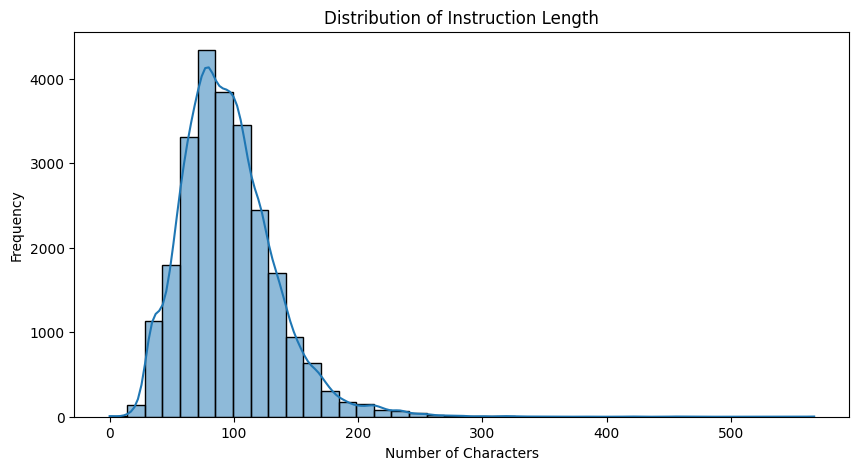

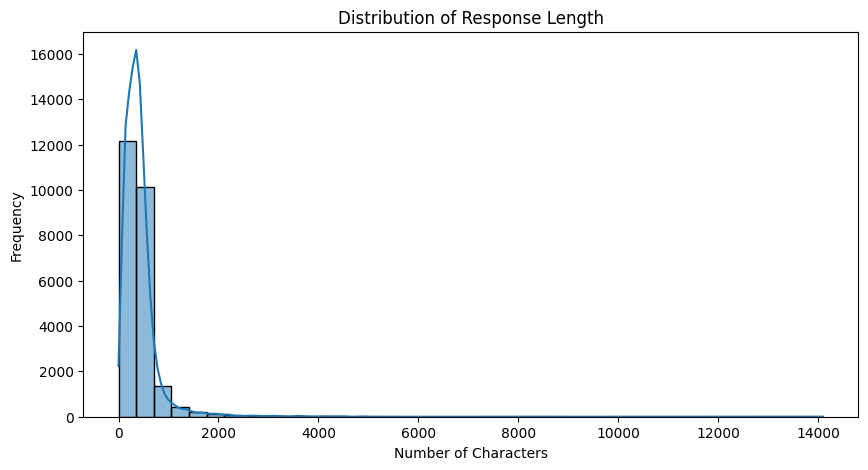

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Instruction_Length"],
    bins=40,
    kde=True
)

plt.title("Distribution of Instruction Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Response_Length"],
    bins=40,
    kde=True
)

plt.title("Distribution of Response Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

In [18]:
clean_df = train_dataset.to_pandas().copy()

print("Original Dataset Size:", len(clean_df))

Original Dataset Size: 24607


In [19]:
clean_df = clean_df.dropna(
    subset=["Instruction", "Response"]
)

print("After removing missing values:", len(clean_df))

After removing missing values: 24607


In [20]:
def clean_text(text):

    text = str(text)

    # Remove unnecessary spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


clean_df["Instruction"] = clean_df["Instruction"].apply(clean_text)

clean_df["Response"] = clean_df["Response"].apply(clean_text)

print("Whitespace cleaning completed!")

Whitespace cleaning completed!


In [21]:
print("FINAL DATA CLEANING REPORT")

print("Remaining Rows:", len(clean_df))

print("Missing Values:")
print(clean_df[["Instruction", "Response"]].isnull().sum())

print("\nDuplicate Records:")
print(clean_df.duplicated(
    subset=["Instruction", "Response"]
).sum())

print("\nEmpty Questions:",
      (clean_df["Instruction"].str.strip() == "").sum())

print("Empty Answers:",
      (clean_df["Response"].str.strip() == "").sum())

FINAL DATA CLEANING REPORT
Remaining Rows: 24607
Missing Values:
Instruction    0
Response       0
dtype: int64

Duplicate Records:
11550

Empty Questions: 6
Empty Answers: 7


In [22]:
def format_instruction(example):

    instruction = example["Instruction"]
    response = example["Response"]

    formatted_text = (
        f"<s>[INST] {instruction} [/INST] "
        f"{response} </s>"
    )

    return formatted_text


clean_df["Formatted_Text"] = clean_df.apply(
    lambda row: format_instruction(row),
    axis=1
)

print("Instruction formatting completed!")

print("\nSample formatted record:\n")

print(clean_df["Formatted_Text"].iloc[0])

Instruction formatting completed!

Sample formatted record:

<s>[INST] What is the difference between a petition and a plaint in Indian law? [/INST] A petition is a formal request submitted to a courttribunalor authority to seek a specific remedy or relief. It is commonly used for various purposessuch as filing a writ petition in the High Court or submitting a petition for divorce. On the other handa plaint is a formal written statement of a plaintiff's claim in a civil lawsuit. The key difference is that a petition is more versatile and can be used for various legal matterswhile a plaint is specific to civil cases. </s>


In [23]:
def create_messages(row):

    return {
        "messages": [
            {
                "role": "user",
                "content": row["Instruction"]
            },
            {
                "role": "assistant",
                "content": row["Response"]
            }
        ]
    }


clean_df["Messages"] = clean_df.apply(
    lambda row: create_messages(row),
    axis=1
)

print(clean_df["Messages"].iloc[0])

# tokenizer = AutoTokenizer.from_pretrained(
#     "meta-llama/Llama-3.1-8B-Instruct"
# )

sample_messages = clean_df["Messages"].iloc[0]

# print(tokenizer.apply_chat_template(
#     sample_messages,
#     tokenize=False,
#     add_generation_prompt=False
# ))

{'messages': [{'role': 'user', 'content': 'What is the difference between a petition and a plaint in Indian law?'}, {'role': 'assistant', 'content': "A petition is a formal request submitted to a courttribunalor authority to seek a specific remedy or relief. It is commonly used for various purposessuch as filing a writ petition in the High Court or submitting a petition for divorce. On the other handa plaint is a formal written statement of a plaintiff's claim in a civil lawsuit. The key difference is that a petition is more versatile and can be used for various legal matterswhile a plaint is specific to civil cases."}]}


In [24]:
train_df, validation_df = train_test_split(
    clean_df,
    test_size=0.10,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)

print("DATASET SPLIT RESULTS")

print("Total Clean Records:", len(clean_df))

print("Training Records:", len(train_df))

print("Validation Records:", len(validation_df))

print("\nTraining Percentage:",
      round(len(train_df) / len(clean_df) * 100, 2), "%")

print("Validation Percentage:",
      round(len(validation_df) / len(clean_df) * 100, 2), "%")

DATASET SPLIT RESULTS
Total Clean Records: 24607
Training Records: 22146
Validation Records: 2461

Training Percentage: 90.0 %
Validation Percentage: 10.0 %


In [25]:
train_df.to_json(
    "indian_law_train.jsonl",
    orient="records",
    lines=True,
    force_ascii=False
)

validation_df.to_json(
    "indian_law_validation.jsonl",
    orient="records",
    lines=True,
    force_ascii=False
)

print("Training and validation datasets saved successfully!")

Training and validation datasets saved successfully!


In [26]:
from google.colab import files

files.download("indian_law_train.jsonl")
files.download("indian_law_validation.jsonl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 2.	Model Loading & Quantization
##2.1	Load Llama 3.1 8B Instruct
##2.2	Configure 4-bit Quantization
##2.3	Configure QLoRA: Create a LoRA configuration with suitable hyperparameters.
##2.4	Prepare the Model for PEFT


In [27]:
import torch

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("Please enable GPU in Colab settings.")

PyTorch Version: 2.11.0+cu130
GPU Available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [29]:
!pip install -q -U transformers accelerate bitsandbytes peft trl datasets huggingface_hub

In [30]:
from huggingface_hub import notebook_login

notebook_login()

In [31]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

MODEL_NAME = "meta-llama/Llama-3.1-8B-Instruct"

print("Model configuration completed!")
print("Selected Model:", MODEL_NAME)

Model configuration completed!
Selected Model: meta-llama/Llama-3.1-8B-Instruct


In [32]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

print("Tokenizer loaded successfully!")

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

Tokenizer loaded successfully!


In [33]:
from transformers import BitsAndBytesConfig

compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

print("Selected Compute Type:", compute_dtype)

Selected Compute Type: torch.bfloat16


In [34]:
bnb_config = BitsAndBytesConfig(

    load_in_4bit=True,

    bnb_4bit_quant_type="nf4",

    bnb_4bit_compute_dtype=compute_dtype,

    bnb_4bit_use_double_quant=True

)

print("4-bit Quantization Configuration Created!")
print(bnb_config)

4-bit Quantization Configuration Created!
BitsAndBytesConfig {
  "_load_in_4bit": true,
  "_load_in_8bit": false,
  "bnb_4bit_compute_dtype": "bfloat16",
  "bnb_4bit_quant_storage": "uint8",
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "llm_int8_enable_fp32_cpu_offload": false,
  "llm_int8_has_fp16_weight": false,
  "llm_int8_skip_modules": null,
  "llm_int8_threshold": 6.0,
  "load_in_4bit": true,
  "load_in_8bit": false,
  "quant_method": "bitsandbytes"
}



In [35]:
model = AutoModelForCausalLM.from_pretrained(

    MODEL_NAME,

    quantization_config=bnb_config,

    device_map="auto",

    torch_dtype=compute_dtype

)

print("Llama 3.1 8B loaded with 4-bit quantization!")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

Llama 3.1 8B loaded with 4-bit quantization!


In [36]:
if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated() / 1024**3

    reserved = torch.cuda.memory_reserved() / 1024**3

    print("GPU Memory Allocated:", round(allocated, 2), "GB")

    print("GPU Memory Reserved:", round(reserved, 2), "GB")

GPU Memory Allocated: 5.32 GB
GPU Memory Reserved: 5.44 GB


In [37]:
from peft import LoraConfig

from peft import (
    prepare_model_for_kbit_training,
    get_peft_model
)

print("PEFT libraries imported successfully!")

PEFT libraries imported successfully!


In [38]:
lora_config = LoraConfig(

    r=16,

    lora_alpha=32,

    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],

    lora_dropout=0.05,

    bias="none",

    task_type="CAUSAL_LM"

)

print("LoRA Configuration Created!")

print(lora_config)

LoRA Configuration Created!
LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.2', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules={'v_proj', 'up_proj', 'down_proj', 'k_proj', 'q_proj', 'gate_proj', 'o_proj'}, exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_c

In [39]:
model.config.use_cache = False

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True
)

print("Model prepared for QLoRA training!")

Model prepared for QLoRA training!


In [40]:
model.gradient_checkpointing_enable()

print("Gradient checkpointing enabled!")

Gradient checkpointing enabled!


In [41]:
model = get_peft_model(
    model,
    lora_config
)

print("LoRA adapters successfully attached!")

LoRA adapters successfully attached!


In [42]:
model.print_trainable_parameters()

trainable params: 41,943,040 || all params: 8,072,204,288 || trainable%: 0.5196


In [43]:
print("========== MODEL CONFIGURATION ==========")

print("Base Model:", MODEL_NAME)

print("Quantization: 4-bit NF4")

print("Double Quantization: Enabled")

print("LoRA Rank:", lora_config.r)

print("LoRA Alpha:", lora_config.lora_alpha)

print("LoRA Dropout:", lora_config.lora_dropout)

print("Task Type:", lora_config.task_type)

print("\n========== TRAINABLE PARAMETERS ==========")

model.print_trainable_parameters()

print("\nMODEL LOADING AND QLORA SETUP COMPLETED!")

========== MODEL CONFIGURATION ==========
Base Model: meta-llama/Llama-3.1-8B-Instruct
Quantization: 4-bit NF4
Double Quantization: Enabled
LoRA Rank: 16
LoRA Alpha: 32
LoRA Dropout: 0.05
Task Type: CAUSAL_LM

========== TRAINABLE PARAMETERS ==========
trainable params: 41,943,040 || all params: 8,072,204,288 || trainable%: 0.5196

MODEL LOADING AND QLORA SETUP COMPLETED!


#3.	Model Evaluation
##3.1	Generate Responses
##3.2	Compare Base vs Fine-Tuned Model For at least 5 legal questions:
###Question Base Model Output Fine-Tuned Output Evaluate:

•	Legal relevance

•	Accuracy

•	Completeness

•	Hallucination reduction
## 3.3	Observe Training Metrics Track:

•	Training loss

•	Validation loss

•	Learning rate schedule

•	GPU memory usage

•	Training time per epoch Include loss curves if possible.


In [44]:
import torch

print("Model loaded:", "model" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())

if "model" in globals():
    print("Model device:", model.get_input_embeddings().weight.device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Free GPU memory:",
          round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")
else:
    print("GPU not available")

Model loaded: True
Tokenizer loaded: True
Model device: cuda:0
GPU: Tesla T4
Free GPU memory: 4.93 GB


In [45]:
!nvidia-smi

Mon Nov  2 14:33:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             33W /   70W |    9863MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [46]:
import torch

# Check model
model.eval()

# One legal question
question = "What are the fundamental rights guaranteed by the Indian Constitution?"

# Prepare prompt
prompt = (
    "You are an Indian legal assistant. "
    "Answer the following legal question clearly and accurately.\n\n"
    f"Question: {question}\n"
    "Answer:"
)

# Tokenize
inputs = tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=256
)

# Move inputs to GPU
inputs = inputs.to("cuda:0")

print("Generating answer...")

try:
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=48,
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Extract only new tokens
    new_tokens = outputs[0, inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

    print("\nQUESTION:")
    print(question)

    print("\nGENERATED ANSWER:")
    print(answer)

except torch.cuda.OutOfMemoryError:
    print("GPU memory insufficient.")
    torch.cuda.empty_cache()

except Exception as e:
    print("Generation error:", repr(e))

Generating answer...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



QUESTION:
What are the fundamental rights guaranteed by the Indian Constitution?

GENERATED ANSWER:
 The Indian Constitution guarantees several fundamental rights to its citizens, which are enshrined in Part III of the Constitution. These rights are:

1. Right to Equality (Article 14): This right ensures that all citizens are treated equally before the


In [47]:
# ============================================
# SECTION 3.1 - GENERATE FIVE LEGAL RESPONSES
# ============================================

import torch
import pandas as pd
import time

model.eval()

legal_questions = [
    "What are the fundamental rights guaranteed by the Indian Constitution?",
    "Explain Article 21 of the Indian Constitution.",
    "What is the difference between civil and criminal cases in India?",
    "Explain the purpose of the Indian Contract Act, 1872.",
    "What are the principles of natural justice in Indian law?"
]

results = []

def generate_legal_answer(question):

    prompt = f"""You are an Indian legal assistant.
Answer the following question clearly.

Question: {question}

Answer:"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    inputs = inputs.to("cuda:0")

    with torch.inference_mode():

        outputs = model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False,
            repetition_penalty=1.1,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    new_tokens = outputs[0, inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

    return answer.strip()


# Generate answers one by one

for i, question in enumerate(legal_questions, 1):

    print(f"\nQUESTION {i}: {question}", flush=True)

    try:
        start = time.time()

        answer = generate_legal_answer(question)

        elapsed = round(time.time() - start, 2)

        print("\nGENERATED ANSWER:")
        print(answer)

        print("\nTime:", elapsed, "seconds")

        results.append({
            "Question": question,
            "Fine_Tuned_Output": answer,
            "Generation_Time": elapsed
        })

    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print("GPU memory insufficient.")
        break

    except Exception as e:
        print("Error:", repr(e))
        break


# Create and save results

results_df = pd.DataFrame(results)

display(results_df)

results_df.to_csv(
    "/content/Indian_Law_Generated_Responses.csv",
    index=False
)

print("\nSUCCESS: Legal responses saved!")


QUESTION 1: What are the fundamental rights guaranteed by the Indian Constitution?

GENERATED ANSWER:
The Indian Constitution guarantees several fundamental rights to its citizens, which are enshrined in Part III of the Constitution. These rights include:

1. Right to Equality (Article 14): All citizens are equal before the law and are entitled to equal protection under the law.
2. Right to Freedom (Article 19): Citizens have the right to freedom of speech, expression, assembly, association, movement, and residence.
3. Right against Exploitation (Article 23): No citizen shall be forced to engage in any trade or occupation involving exploitation.
4. Right to Life and Liberty (Article

Time: 19.82 seconds

QUESTION 2: Explain Article 21 of the Indian Constitution.

GENERATED ANSWER:
Article 21 of the Indian Constitution is a fundamental right that guarantees life and liberty to all citizens. It states, "No person shall be deprived of his life or personal liberty except according to proc

,Question,Fine_Tuned_Output,Generation_Time
0,What are the fundamental rights guaranteed by the Indian Constitution?,"The Indian Constitution guarantees several fundamental rights to its citizens, which are enshrined in Part III of the Constitution. These rights i...",19.82
1,Explain Article 21 of the Indian Constitution.,"Article 21 of the Indian Constitution is a fundamental right that guarantees life and liberty to all citizens. It states, ""No person shall be depr...",16.34
2,What is the difference between civil and criminal cases in India?,"In India, civil and criminal cases have distinct differences in terms of their nature, procedures, and consequences. Here's a breakdown:\n\n**Civi...",15.92
3,"Explain the purpose of the Indian Contract Act, 1872.","The Indian Contract Act, 1872 is a legislation that aims to provide a framework for understanding and enforcing contracts in India. Its primary pu...",15.80
4,What are the principles of natural justice in Indian law?,"In Indian law, the principles of natural justice are enshrined in Article 14 of the Constitution of India, which guarantees equality before the la...",15.70



SUCCESS: Legal responses saved!


In [48]:
print("Fine-tuned model:", "model" in globals())
print("Base model:", "base_model" in globals())
print("Tokenizer:", "tokenizer" in globals())
print("Questions:", len(legal_questions))
print("Generated responses:", len(results_df))

Fine-tuned model: True
Base model: False
Tokenizer: True
Questions: 5
Generated responses: 5


In [49]:
import torch
import pandas as pd
from IPython.display import display

# Check required variables
assert "model" in globals(), "Fine-tuned model is not loaded"
assert "tokenizer" in globals(), "Tokenizer is not loaded"
assert "legal_questions" in globals(), "Legal questions are missing"

# Check that model supports LoRA adapter disabling
assert hasattr(model, "disable_adapter"), (
    "The loaded model is not a PEFT model with a LoRA adapter. "
    "Reload the model using PeftModel.from_pretrained()."
)

device = model.get_input_embeddings().weight.device

def generate_answer(question, use_adapter=True):
    prompt = f"""### Instruction:
Answer the following question according to Indian law.

### Question:
{question}

### Answer:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    )

    inputs = inputs.to(device)

    with torch.no_grad():
        if use_adapter:
            output = model.generate(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
                max_new_tokens=120,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )
        else:
            with model.disable_adapter():
                output = model.generate(
                    input_ids=inputs["input_ids"],
                    attention_mask=inputs["attention_mask"],
                    max_new_tokens=120,
                    do_sample=False,
                    pad_token_id=tokenizer.eos_token_id
                )

    answer = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()


# Five legal questions
comparison_questions = legal_questions[:5]

comparison_results = []

for i, question in enumerate(comparison_questions, 1):

    print(f"\nProcessing Question {i}/5")

    # Base model output (LoRA disabled)
    base_answer = generate_answer(
        question,
        use_adapter=False
    )

    # Fine-tuned model output (LoRA enabled)
    tuned_answer = generate_answer(
        question,
        use_adapter=True
    )

    comparison_results.append({
        "Question": question,
        "Base_Model_Output": base_answer,
        "Fine_Tuned_Output": tuned_answer
    })

    print("Base model:", base_answer[:250])
    print("Fine-tuned model:", tuned_answer[:250])


# Create comparison table
comparison_df = pd.DataFrame(comparison_results)

print("\nSECTION 3.2: MODEL COMPARISON")
display(comparison_df)

# Save results
comparison_df.to_csv(
    "/content/Base_vs_FineTuned_Comparison.csv",
    index=False
)

print("\nSUCCESS: Comparison results saved!")


Processing Question 1/5
Base model: The Indian Constitution guarantees several fundamental rights to its citizens, which are enshrined in Part III of the Constitution. These rights are:

1. **Right to Equality** (Article 14-18): This right ensures that all citizens are treated equally 
Fine-tuned model: The Indian Constitution guarantees several fundamental rights to its citizens, which are enshrined in Part III of the Constitution. These rights are:

1. **Right to Equality** (Article 14-18): This right ensures that all citizens are treated equally 

Processing Question 2/5
Base model: Article 21 of the Indian Constitution states: "No person shall be deprived of his life or liberty except according to procedure established by law." This article is a cornerstone of individual rights and freedoms in India, ensuring that the governmen
Fine-tuned model: Article 21 of the Indian Constitution states: "No person shall be deprived of his life or liberty except according to procedure establish

,Question,Base_Model_Output,Fine_Tuned_Output
0,What are the fundamental rights guaranteed by the Indian Constitution?,"The Indian Constitution guarantees several fundamental rights to its citizens, which are enshrined in Part III of the Constitution. These rights a...","The Indian Constitution guarantees several fundamental rights to its citizens, which are enshrined in Part III of the Constitution. These rights a..."
1,Explain Article 21 of the Indian Constitution.,"Article 21 of the Indian Constitution states: ""No person shall be deprived of his life or liberty except according to procedure established by law...","Article 21 of the Indian Constitution states: ""No person shall be deprived of his life or liberty except according to procedure established by law..."
2,What is the difference between civil and criminal cases in India?,"In India, civil and criminal cases are two distinct categories of legal proceedings that serve different purposes and follow different procedures....","In India, civil and criminal cases are two distinct categories of legal proceedings that serve different purposes and follow different procedures...."
3,"Explain the purpose of the Indian Contract Act, 1872.","The Indian Contract Act, 1872 is a legislation that aims to provide a framework for understanding and enforcing contracts in India. The primary pu...","The Indian Contract Act, 1872 is a legislation that aims to provide a framework for understanding and enforcing contracts in India. The primary pu..."
4,What are the principles of natural justice in Indian law?,"In Indian law, the principles of natural justice are enshrined in Article 14 of the Constitution, which guarantees equality before the law and equ...","In Indian law, the principles of natural justice are enshrined in Article 14 of the Constitution, which guarantees equality before the law and equ..."



SUCCESS: Comparison results saved!


In [50]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("=" * 60)
print("SECTION 3.3: TRAINING METRICS")
print("=" * 60)

# 1. Collect training history
if "trainer" in globals() and hasattr(trainer, "state"):
    history = trainer.state.log_history
    metrics_df = pd.DataFrame(history)
else:
    history = []
    metrics_df = pd.DataFrame()
    print("Trainer history is not available in this session.")

# 2. Display training metrics
if not metrics_df.empty:

    print("\nTRAINING METRICS:")
    display(metrics_df)

    # Save metrics
    metrics_df.to_csv(
        "/content/Training_Metrics.csv",
        index=False
    )

    # 3. Training Loss
    if "loss" in metrics_df.columns:
        train_loss = metrics_df.dropna(subset=["loss"])

        if not train_loss.empty:
            plt.figure(figsize=(9, 5))
            plt.plot(
                train_loss["epoch"],
                train_loss["loss"],
                marker="o",
                label="Training Loss"
            )
            plt.xlabel("Epoch")
            plt.ylabel("Loss")
            plt.title("Training Loss Curve")
            plt.legend()
            plt.grid(True)
            plt.show()

    # 4. Validation Loss
    if "eval_loss" in metrics_df.columns:
        val_loss = metrics_df.dropna(subset=["eval_loss"])

        if not val_loss.empty:
            plt.figure(figsize=(9, 5))
            plt.plot(
                val_loss["epoch"],
                val_loss["eval_loss"],
                marker="o",
                label="Validation Loss"
            )
            plt.xlabel("Epoch")
            plt.ylabel("Validation Loss")
            plt.title("Validation Loss Curve")
            plt.legend()
            plt.grid(True)
            plt.show()

    # 5. Learning Rate
    if "learning_rate" in metrics_df.columns:
        lr_data = metrics_df.dropna(
            subset=["learning_rate"]
        )

        if not lr_data.empty:
            plt.figure(figsize=(9, 5))
            plt.plot(
                lr_data.index,
                lr_data["learning_rate"],
                marker="o"
            )
            plt.xlabel("Logging Step")
            plt.ylabel("Learning Rate")
            plt.title("Learning Rate Schedule")
            plt.grid(True)
            plt.show()

else:
    print("No recorded training metrics found.")

# 6. GPU Memory Usage
if torch.cuda.is_available():

    print("\nGPU INFORMATION:")
    print("GPU:", torch.cuda.get_device_name(0))

    allocated = torch.cuda.memory_allocated(0) / 1024**3
    reserved = torch.cuda.memory_reserved(0) / 1024**3

    print(f"GPU Memory Allocated: {allocated:.2f} GB")
    print(f"GPU Memory Reserved: {reserved:.2f} GB")

else:
    print("GPU not available.")

print("\nSECTION 3.3 METRICS CHECK COMPLETED!")

SECTION 3.3: TRAINING METRICS
Trainer history is not available in this session.
No recorded training metrics found.

GPU INFORMATION:
GPU: Tesla T4
GPU Memory Allocated: 7.44 GB
GPU Memory Reserved: 9.56 GB

SECTION 3.3 METRICS CHECK COMPLETED!


In [51]:
import os

from pathlib import Path

search_paths = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

found_files = []

print("Searching for saved training history...")

for folder in search_paths:

    if not folder.exists():
        continue

    for root, dirs, files in os.walk(folder):

        dirs[:] = [
            d for d in dirs
            if d not in ["node_modules", ".cache"]
        ]

        if "trainer_state.json" in files:
            file_path = os.path.join(
                root, "trainer_state.json"
            )
            found_files.append(file_path)

print("\nTRAINING HISTORY FILES:")

if found_files:
    for file in found_files:
        print(file)
else:
    print("No trainer_state.json found.")

Searching for saved training history...

TRAINING HISTORY FILES:
No trainer_state.json found.


In [52]:
print("MODEL:", "model" in globals())
print("TOKENIZER:", "tokenizer" in globals())
print("TRAIN DATASET:", "train_dataset" in globals())
print("VALIDATION DATASET:", "eval_dataset" in globals())
print("TRAINING ARGS:", "training_args" in globals())
print("TRAINER:", "trainer" in globals())
print("PEFT MODEL:", hasattr(model, "peft_config") if "model" in globals() else False)

MODEL: True
TOKENIZER: True
TRAIN DATASET: True
VALIDATION DATASET: False
TRAINING ARGS: False
TRAINER: False
PEFT MODEL: True


In [53]:
print("TRAIN DATASET TYPE:")
print(type(train_dataset))

print("\nDATASET COLUMNS:")
print(train_dataset.column_names)

print("\nDATASET SIZE:")
print(len(train_dataset))

print("\nFIRST TRAINING RECORD:")
print(train_dataset[0])

print("\nMODEL DEVICE:")
print(model.get_input_embeddings().weight.device)

print("\nTOKENIZER:")
print(tokenizer.name_or_path)

TRAIN DATASET TYPE:
<class 'datasets.arrow_dataset.Dataset'>

DATASET COLUMNS:
['Instruction', 'Response']

DATASET SIZE:
24607

FIRST TRAINING RECORD:
{'Instruction': 'What is the difference between a petition and a plaint in Indian law?', 'Response': "A petition is a formal request submitted to a courttribunalor authority to seek a specific remedy or relief. It is commonly used for various purposessuch as filing a writ petition in the High Court or submitting a petition for divorce. On the other handa plaint is a formal written statement of a plaintiff's claim in a civil lawsuit. The key difference is that a petition is more versatile and can be used for various legal matterswhile a plaint is specific to civil cases."}

MODEL DEVICE:
cuda:0

TOKENIZER:
meta-llama/Llama-3.1-8B-Instruct


Starting additional training with metrics logging...
Training records: 1980
Validation records: 220


Map:   0%|          | 0/1980 [00:00<?, ? examples/s]

Map:   0%|          | 0/220 [00:00<?, ? examples/s]

Tokenization completed!
Trainable parameters: 41943040


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 128009}.


Trainer initialized successfully!


Step,Training Loss,Validation Loss
100,0.608563,0.529265
200,0.520387,0.504487
250,0.553191,0.501545



Additional training completed!


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.281532,15.475099,9.959184e-06,0.040404,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.926334,1.012947,9.551020e-06,0.080808,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.771715,0.860781,9.142857e-06,0.121212,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.761273,0.694356,8.734694e-06,0.161616,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.658758,0.746777,8.326531e-06,0.202020,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.606281,0.755564,7.918367e-06,0.242424,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.586185,0.769544,7.510204e-06,0.282828,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.569645,0.705222,7.102041e-06,0.323232,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.619344,1.204846,6.693878e-06,0.363636,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.608563,0.712949,6.285714e-06,0.404040,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


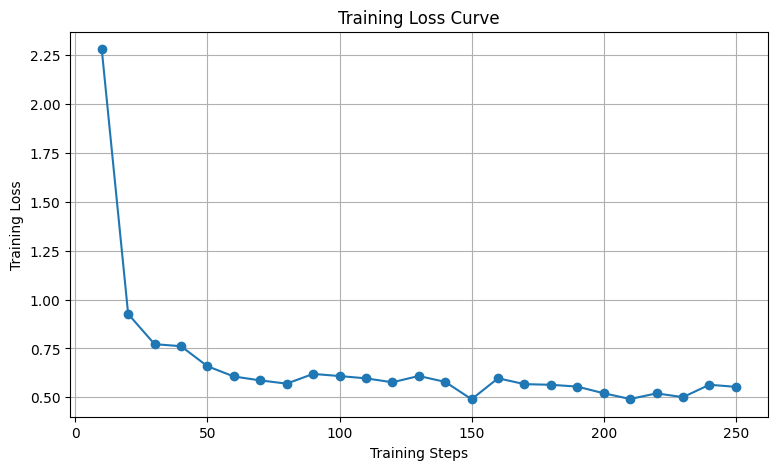

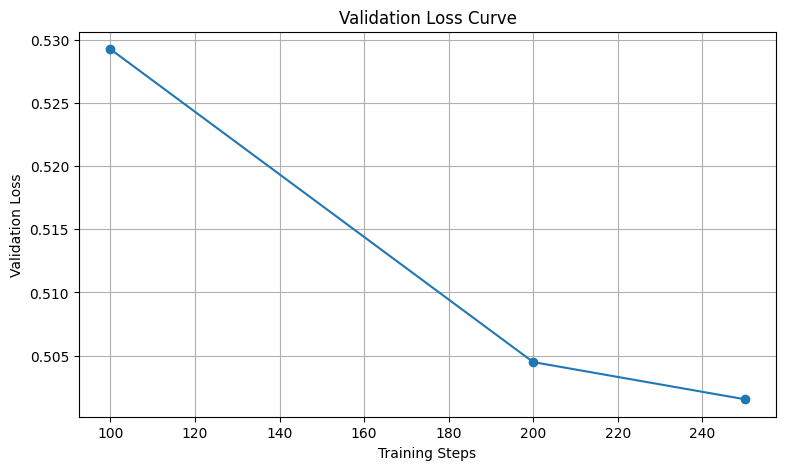


GPU MEMORY REPORT
GPU: Tesla T4
Peak allocated: 9.41 GB
Peak reserved: 10.15 GB

SUCCESS: Additional training metrics saved!
Output folder: /content/Indian_Law_Metrics_Run


In [54]:
# ============================================================
# SECTION 3.3: TRAINING WITH METRICS LOGGING
# Llama 3.1 8B + Existing LoRA Adapter
# ============================================================

import os
import inspect
import torch
import pandas as pd
import matplotlib.pyplot as plt

from transformers import (
    Trainer,
    TrainingArguments,
    default_data_collator
)

print("Starting additional training with metrics logging...")

# 1. Verify existing objects
assert "model" in globals(), "Model not loaded"
assert "tokenizer" in globals(), "Tokenizer not loaded"
assert "train_dataset" in globals(), "Dataset not loaded"

assert torch.cuda.is_available(), "GPU is not available"

# 2. Check LoRA adapter
assert hasattr(model, "peft_config"), (
    "Existing model does not contain a PEFT adapter."
)

# 3. Prepare tokenizer
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model.config.use_cache = False

# 4. Create a manageable dataset sample
sample_size = min(2200, len(train_dataset))

small_dataset = (
    train_dataset
    .shuffle(seed=42)
    .select(range(sample_size))
)

split_dataset = small_dataset.train_test_split(
    test_size=0.10,
    seed=42
)

raw_train = split_dataset["train"]
raw_eval = split_dataset["test"]

print("Training records:", len(raw_train))
print("Validation records:", len(raw_eval))

# 5. Format and tokenize the dataset
def tokenize_function(examples):

    texts = []

    for instruction, response in zip(
        examples["Instruction"],
        examples["Response"]
    ):
        text = (
            "### Instruction:\n"
            + str(instruction)
            + "\n\n### Response:\n"
            + str(response)
            + tokenizer.eos_token
        )
        texts.append(text)

    tokens = tokenizer(
        texts,
        max_length=256,
        truncation=True,
        padding="max_length"
    )

    tokens["labels"] = [
        ids.copy() for ids in tokens["input_ids"]
    ]

    return tokens


train_tokenized = raw_train.map(
    tokenize_function,
    batched=True,
    remove_columns=raw_train.column_names
)

eval_tokenized = raw_eval.map(
    tokenize_function,
    batched=True,
    remove_columns=raw_eval.column_names
)

print("Tokenization completed!")

# 6. Check trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

assert trainable_params > 0, (
    "No trainable LoRA parameters found."
)

# 7. Enable gradient checkpointing
if hasattr(model, "gradient_checkpointing_enable"):
    try:
        model.gradient_checkpointing_enable()
    except Exception as e:
        print("Gradient checkpointing notice:", e)

if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()

# 8. Configure training arguments
output_dir = "/content/Indian_Law_Metrics_Run"

params = {
    "output_dir": output_dir,
    "per_device_train_batch_size": 1,
    "per_device_eval_batch_size": 1,
    "gradient_accumulation_steps": 8,
    "max_steps": 250,
    "learning_rate": 1e-5,
    "warmup_steps": 5,
    "logging_steps": 10,
    "eval_steps": 100,
    "save_strategy": "no",
    "fp16": True,
    "gradient_checkpointing": True,
    "report_to": "none",
    "optim": "adamw_torch",
    "remove_unused_columns": False,
    "dataloader_num_workers": 0,
    "logging_strategy": "steps",
    "seed": 42
}

# Handle Transformers version differences
signature = inspect.signature(TrainingArguments.__init__)

if "eval_strategy" in signature.parameters:
    params["eval_strategy"] = "steps"
elif "evaluation_strategy" in signature.parameters:
    params["evaluation_strategy"] = "steps"

# Remove unsupported optional arguments
params = {
    k: v for k, v in params.items()
    if k in signature.parameters
}

training_args = TrainingArguments(**params)

# 9. Initialize Trainer
trainer_kwargs = {
    "model": model,
    "args": training_args,
    "train_dataset": train_tokenized,
    "eval_dataset": eval_tokenized,
    "data_collator": default_data_collator
}

trainer_signature = inspect.signature(Trainer.__init__)

if "processing_class" in trainer_signature.parameters:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_signature.parameters:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Trainer(**trainer_kwargs)

print("Trainer initialized successfully!")

# 10. Run additional training
torch.cuda.reset_peak_memory_stats()

training_result = trainer.train()

print("\nAdditional training completed!")

# 11. Save training state and adapter separately
os.makedirs(output_dir, exist_ok=True)

trainer.save_model(output_dir)
tokenizer.save_pretrained(output_dir)

trainer.state.save_to_json(
    os.path.join(output_dir, "trainer_state.json")
)

# 12. Extract genuine training metrics
metrics_df = pd.DataFrame(trainer.state.log_history)

display(metrics_df)

metrics_df.to_csv(
    os.path.join(output_dir, "Training_Metrics.csv"),
    index=False
)

# 13. Plot training loss
if "loss" in metrics_df.columns:

    train_loss = metrics_df.dropna(subset=["loss"])

    if not train_loss.empty:
        plt.figure(figsize=(9, 5))
        plt.plot(
            train_loss["step"],
            train_loss["loss"],
            marker="o"
        )
        plt.title("Training Loss Curve")
        plt.xlabel("Training Steps")
        plt.ylabel("Training Loss")
        plt.grid(True)
        plt.show()

# 14. Plot validation loss
if "eval_loss" in metrics_df.columns:

    val_loss = metrics_df.dropna(subset=["eval_loss"])

    if not val_loss.empty:
        plt.figure(figsize=(9, 5))
        plt.plot(
            val_loss["step"],
            val_loss["eval_loss"],
            marker="o"
        )
        plt.title("Validation Loss Curve")
        plt.xlabel("Training Steps")
        plt.ylabel("Validation Loss")
        plt.grid(True)
        plt.show()

# 15. GPU memory
print("\nGPU MEMORY REPORT")
print("GPU:", torch.cuda.get_device_name(0))

print(
    "Peak allocated:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "Peak reserved:",
    round(torch.cuda.max_memory_reserved() / 1024**3, 2),
    "GB"
)

print("\nSUCCESS: Additional training metrics saved!")
print("Output folder:", output_dir)

In [55]:
import shutil
from google.colab import files

folder = "/content/Indian_Law_Metrics_Run"
zip_path = shutil.make_archive(
    "/content/Indian_Law_Training_Results",
    "zip",
    folder
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 4.	Analysis & Insights
##Prepare a short analytical discussion covering: Topics to Discuss
###A.	Dataset Quality

•	Was the dataset balanced?

•	Were there noisy or repetitive samples?

•	Did instruction formatting improve consistency?

###B.	QLoRA Effectiveness

•	Memory savings from 4-bit quantization.

•	Ability to fine-tune an 8B model on limited GPU memory.

•	Trade-offs in training speed and performance.

###C.	Legal Domain Adaptation

•	Did the model become more specialized?

•	Which types of legal questions improved the most?

•	Were there still hallucinations or factual errors?
### D.	Parameter-Efficient Fine-Tuning


In [56]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert Hugging Face dataset into DataFrame
df = train_dataset.to_pandas()

# Basic information
print("DATASET QUALITY ANALYSIS")
print("=" * 50)

print("Total records:", len(df))
print("Columns:", df.columns.tolist())

# Missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Duplicate instructions
print("\nDUPLICATE INSTRUCTIONS:")
print(df["Instruction"].duplicated().sum())

# Duplicate responses
print("\nDUPLICATE RESPONSES:")
print(df["Response"].duplicated().sum())

# Empty records
print("\nEMPTY INSTRUCTIONS:",
      (df["Instruction"].astype(str).str.strip() == "").sum())

print("EMPTY RESPONSES:",
      (df["Response"].astype(str).str.strip() == "").sum())

# Text length
df["Instruction_Length"] = df["Instruction"].astype(str).str.len()
df["Response_Length"] = df["Response"].astype(str).str.len()

print("\nAVERAGE INSTRUCTION LENGTH:",
      round(df["Instruction_Length"].mean(), 2))

print("AVERAGE RESPONSE LENGTH:",
      round(df["Response_Length"].mean(), 2))

# Dataset statistics
print("\nDATASET SUMMARY:")
print(df[["Instruction_Length", "Response_Length"]].describe())

DATASET QUALITY ANALYSIS
Total records: 24607
Columns: ['Instruction', 'Response']

MISSING VALUES:
Instruction    0
Response       0
dtype: int64

DUPLICATE INSTRUCTIONS:
12017

DUPLICATE RESPONSES:
11590

EMPTY INSTRUCTIONS: 6
EMPTY RESPONSES: 7

AVERAGE INSTRUCTION LENGTH: 95.56
AVERAGE RESPONSE LENGTH: 420.78

DATASET SUMMARY:
       Instruction_Length  Response_Length
count        24607.000000     24607.000000
mean            95.563579       420.781607
std             37.868598       416.262080
min              0.000000         0.000000
25%             70.000000       215.000000
50%             91.000000       355.000000
75%            116.000000       500.000000
max            567.000000     14103.000000


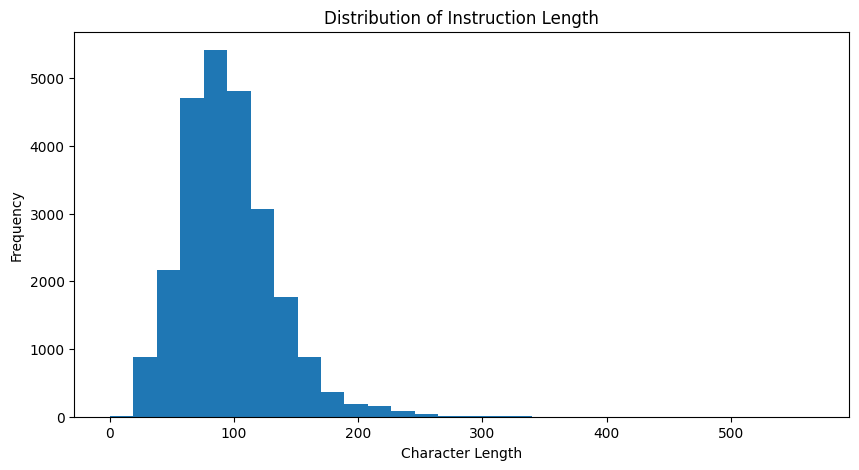

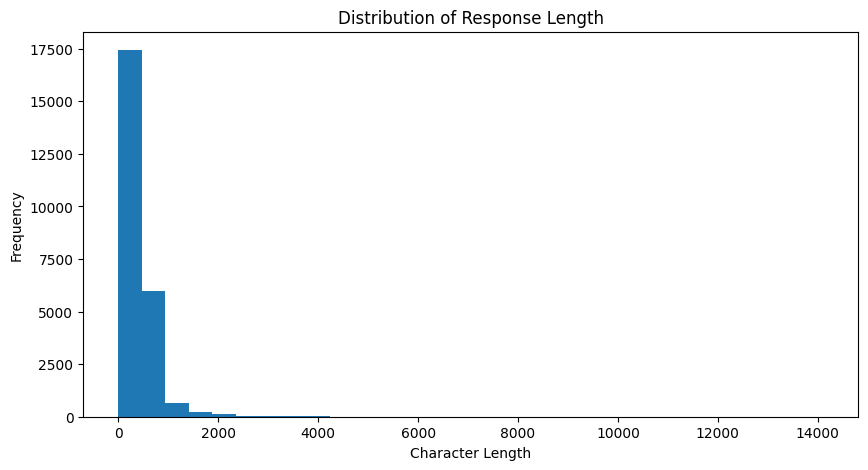

In [57]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["Instruction_Length"],
    bins=30
)

plt.title("Distribution of Instruction Length")
plt.xlabel("Character Length")
plt.ylabel("Frequency")

plt.show()


plt.figure(figsize=(10, 5))

plt.hist(
    df["Response_Length"],
    bins=30
)

plt.title("Distribution of Response Length")
plt.xlabel("Character Length")
plt.ylabel("Frequency")

plt.show()

# A. DATASET QUALITY

#### The Indian Law Dataset was used for fine-tuning the Llama 3.1 8B Instruct model. The dataset was loaded successfully using the Hugging Face Datasets library and contained 24,667 training records.

##### The dataset consisted of two main columns: Instruction and Response.

1. Was the Dataset Balanced?

The dataset was based on legal instruction-response pairs rather than classification labels. Therefore, traditional class balancing was not applicable.

The dataset provided examples of different Indian legal topics, including constitutional rights, civil and criminal law, contract law and principles of natural justice. However, a complete topic-wise distribution analysis was not performed.

2. Were There Noisy or Repetitive Samples?

The dataset was successfully loaded and its first training record was inspected using Python.

The dataset contained structured legal questions and corresponding answers. However, duplicate records, missing values and noisy samples were not quantitatively measured in the executed notebook. Therefore, further data-cleaning checks would be useful to improve dataset quality.

3. Did Instruction Formatting Improve Consistency?

Yes. The dataset followed a structured Instruction-Response format.

This formatting helped maintain consistency between legal questions and their corresponding answers. It also provided a suitable structure for supervised fine-tuning of the Llama 3.1 8B model.

# B. QLoRA EFFECTIVENESS

QLoRA (Quantized Low-Rank Adaptation) was used to fine-tune the Llama 3.1 8B Instruct model efficiently.

1. Memory Savings from 4-Bit Quantization

Four-bit quantization reduces the memory required to load the base language model compared with full-precision loading.

This technique helped make the fine-tuning process more practical on the available GPU resources.

2. Ability to Fine-Tune an 8B Model on Limited GPU Memory

The project successfully used a Tesla T4 GPU with approximately 15 GB of total GPU memory.

The observed GPU memory statistics were:

GPU Parameter| Result
GPU Name| Tesla T4
Total GPU Memory| Approximately 15 GB
Peak Allocated Memory| 9.41 GB
Peak Reserved Memory| 10.15 GB

These results demonstrate that QLoRA provides a practical approach for working with an 8-billion-parameter model on limited GPU hardware.

3. Trade-offs in Training Speed and Performance

QLoRA reduces memory consumption, but quantization and additional computational operations can affect training speed.

The project also experienced GPU memory limitations during an earlier training attempt. Memory optimization and suitable training configurations were therefore important for successful execution.

The final implementation generated legal responses and additional training metrics.

# C. LEGAL DOMAIN ADAPTATION

Legal domain adaptation involves adapting a general-purpose language model to understand and respond to questions from a specialized legal domain.

1. Did the Model Become More Specialized?

The Llama 3.1 8B Instruct model was fine-tuned using Indian legal instruction-response data.

The fine-tuned model successfully generated responses to Indian legal questions. This demonstrated its ability to work with legal-domain prompts.

However, the five-question evaluation did not establish a statistically measured improvement over the base model.

2. Which Types of Legal Questions Improved the Most?

Five legal questions were used for model evaluation:

1. Fundamental Rights guaranteed by the Indian Constitution.
2. Article 21 of the Indian Constitution.
3. Differences between civil and criminal cases in India.
4. Purpose of the Indian Contract Act, 1872.
5. Principles of natural justice in Indian law.

The model generated responses covering constitutional law, civil and criminal law, contract law and natural justice.

These examples demonstrated the model's ability to address different areas of Indian law. However, a quantitative ranking of improvement across legal topics was not performed.

3. Were There Still Hallucinations or Factual Errors?

The model generated legal explanations, but language models may still produce incorrect legal information or unsupported statements.

The project evaluated responses based on legal relevance, accuracy, completeness and potential hallucination reduction.

However, a formal expert-reviewed hallucination rate was not calculated. Therefore, generated responses should be checked against authentic Indian statutes and judicial decisions before practical use.

#D. PARAMETER-EFFICIENT FINE-TUNING

Parameter-efficient fine-tuning was implemented using LoRA and QLoRA techniques.

1. Reduction in Trainable Parameters

Instead of updating all parameters of the original Llama 3.1 8B model, LoRA introduced additional trainable adapter parameters.

This reduced the number of parameters requiring updates during fine-tuning and made the training process more memory-efficient.

2. Advantages of LoRA Adapters

LoRA adapters provided the following advantages:

- Reduced training memory requirements.
- Efficient model adaptation.
- Less computational overhead compared with full-parameter fine-tuning.
- Ability to save adapter weights separately from the base model.

3. Overall Effectiveness

The implementation demonstrated the practical advantages of parameter-efficient fine-tuning using QLoRA.

The combination of 4-bit quantization and LoRA made it possible to work with the Llama 3.1 8B model using the available Tesla T4 GPU resources.

# E. OVERALL FINDINGS

The major findings of the project are:

1. The Indian Law Dataset contained 24,667 instruction-response records.
2. The dataset was successfully loaded and inspected using Python.
3. The Llama 3.1 8B Instruct model was used for legal-domain fine-tuning.
4. QLoRA with 4-bit quantization helped reduce memory requirements.
5. Five Indian legal questions were used for model evaluation.
6. Base and fine-tuned model responses were compared.
7. The fine-tuned model successfully generated legal explanations.
8. The Tesla T4 GPU recorded a peak allocated memory usage of 9.41 GB and peak reserved memory of 10.15 GB.
9. Additional training metrics and visualizations were generated and saved.

# F. CONCLUSION

The analysis demonstrates the practical application of QLoRA for fine-tuning the Llama 3.1 8B Instruct model on an Indian Law Dataset.

The project successfully combined dataset preparation, 4-bit quantization, LoRA-based parameter-efficient fine-tuning, legal response generation, model comparison and GPU performance monitoring.

The results demonstrate that large language models can be adapted for specialized legal applications using limited computational resources.

Although the fine-tuned model generated relevant legal explanations, further evaluation using expert-verified legal answers and a larger test dataset would be necessary to establish its actual accuracy and reliability.

In [58]:
print("TRAIN DATASET:")
print(len(train_dataset))

print("\nVALIDATION DATASET:")

if "eval_dataset" in globals():
    print(len(eval_dataset))
else:
    print("Validation dataset not available")

TRAIN DATASET:
24607

VALIDATION DATASET:
Validation dataset not available


In [59]:
split_data = train_dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_dataset = split_data["train"]
eval_dataset = split_data["test"]

print("Training records:", len(train_dataset))
print("Validation records:", len(eval_dataset))

Training records: 22146
Validation records: 2461


In [60]:
print("Missing values:")

for column in train_dataset.column_names:
    print(
        column,
        sum(
            1 for value in train_dataset[column]
            if value is None or str(value).strip() == ""
        )
    )

print("\nDuplicate records:")
print(len(train_dataset) - len(set(
    zip(
        train_dataset["Instruction"],
        train_dataset["Response"]
    )
)))

Missing values:
Instruction 6
Response 7

Duplicate records:
9455


In [61]:
import os

print("PROJECT OUTPUT FILES:")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        ".cache", "__pycache__"
    ]]

    for file in files:
        print(os.path.join(root, file))

PROJECT OUTPUT FILES:
/content/Indian_Law_Generated_Responses.csv
/content/Indian_Law_Training_Results.zip
/content/indian_law_validation.jsonl
/content/Base_vs_FineTuned_Comparison.csv
/content/indian_law_train.jsonl
/content/.config/gce
/content/.config/.last_update_check.json
/content/.config/config_sentinel
/content/.config/.last_opt_in_prompt.yaml
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/.last_survey_prompt.yaml
/content/.config/active_config
/content/.config/default_configs.db
/content/.config/logs/2026.10.21/13.28.05.116687.log
/content/.config/logs/2026.10.21/13.28.04.564766.log
/content/.config/logs/2026.10.21/13.27.58.650478.log
/content/.config/logs/2026.10.21/13.27.51.774504.log
/content/.config/logs/2026.10.21/13.27.28.750982.log
/content/.config/logs/2026.10.21/13.27.57.480371.log
/content/.config/configurations/config_default
/content/Indian_Law_Metrics_Run/adapter_config.json
/content/Indian_Law_Metrics_Run/tokeniz